In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Loading and inspecting the data

In [2]:
census_raw = pd.read_csv("Adult Census Income.csv")
census_raw.shape #checking the number of rows and columns

(32561, 15)

In [3]:
census_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [4]:
census_raw.head(10) #first 10 rows

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K


In [5]:
census_raw.describe() #min,max and mean

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


## Checking for missing values and duplicates

In [6]:
census_raw.isna().sum() #looking for missing values

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [7]:
(census_raw == "?").sum() #some missing values could have been written as '?'

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [8]:
census_raw.duplicated().sum() #looking for duplicated

24

In [9]:
round(census_raw["income"].value_counts(normalize=True) * 100, 1) # checking percentage of people in each group of income

income
<=50K    75.9
>50K     24.1
Name: proportion, dtype: float64

## Cleaning the data

In [10]:
census = pd.read_csv("Adult Census Income.csv", na_values="?") # ? becoming missing values
census.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [11]:
census = census.dropna() #removeing the rows with missing values
census.duplicated().sum() #looking for duplicates

23

In [12]:
census = census.drop_duplicates() #deleting duplicates
len(census) #rows left

30139

In [13]:
census = census.drop(columns=["fnlwgt", "education"]) #removing not needed columns

for col in census.columns: #delete the extras spaces
    if census[col].dtype == "object" or census[col].dtype == "str":
        census[col] = census[col].str.strip()
#putting other countries besides the US to the group other
census["native.country"] = census["native.country"].where(census["native.country"] == "United-States", "Other")

for col in census.columns: #text into categories
    if census[col].dtype == "object" or census[col].dtype == "str":
        census[col] = census[col].astype("category")

census.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30139 entries, 1 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             30139 non-null  int64   
 1   workclass       30139 non-null  category
 2   education.num   30139 non-null  int64   
 3   marital.status  30139 non-null  category
 4   occupation      30139 non-null  category
 5   relationship    30139 non-null  category
 6   race            30139 non-null  category
 7   sex             30139 non-null  category
 8   capital.gain    30139 non-null  int64   
 9   capital.loss    30139 non-null  int64   
 10  hours.per.week  30139 non-null  int64   
 11  native.country  30139 non-null  category
 12  income          30139 non-null  category
dtypes: category(8), int64(5)
memory usage: 1.6 MB


In [14]:
census.shape

(30139, 13)

## Outliers

In [15]:
numeric_cols = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
def count_outliers(x): #counting outliers
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    return ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
outlier_table = pd.DataFrame({ #table that shows the number and percentage of outliers
    "outliers": [count_outliers(census[col]) for col in numeric_cols]
}, index=numeric_cols)
outlier_table["percent"] = round(outlier_table["outliers"] / len(census) * 100, 1)
outlier_table

,outliers,percent
age,168,0.6
education.num,193,0.6
capital.gain,2538,8.4
capital.loss,1427,4.7
hours.per.week,7947,26.4


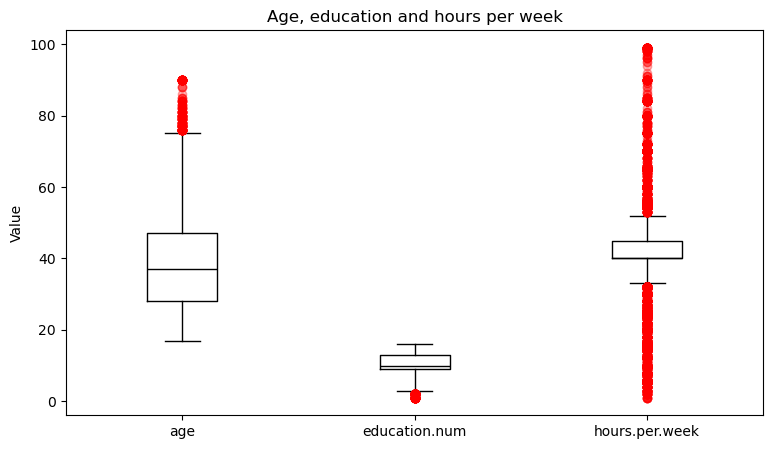

In [16]:
#boxplot, red dots = outliers
census[["age", "education.num", "hours.per.week"]].plot(
    kind="box", figsize=(9, 5), color="black",
    flierprops={"markerfacecolor": "red", "markeredgecolor": "red", "alpha": 0.3})
plt.title("Age, education and hours per week")
plt.ylabel("Value")
plt.show()

In [17]:
#checking gain and loss in the capital
print((census["capital.gain"] == 0).sum() / len(census) * 100)
print((census["capital.loss"] == 0).sum() / len(census) * 100)
print((census["capital.gain"] == 99999).sum())

91.579017220213
95.26527091144365
148


## EDA

In [18]:
census["income"].value_counts() #how many people in each income group

income
<=50K    22633
>50K      7506
Name: count, dtype: int64

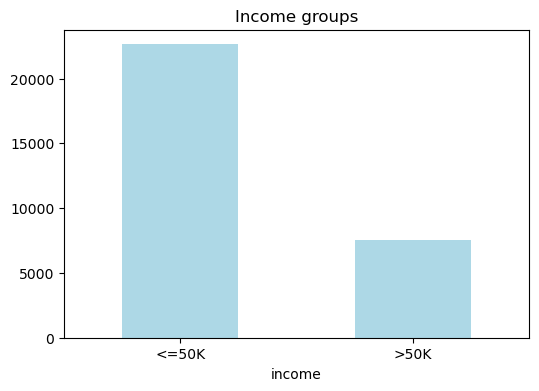

In [19]:
census["income"].value_counts().plot(kind="bar", color="lightblue", figsize=(6, 4))
plt.title("Income groups")
plt.xticks(rotation=0)
plt.show()

In [20]:
census["age"].describe() #age

count    30139.000000
mean        38.441720
std         13.131426
min         17.000000
25%         28.000000
50%         37.000000
75%         47.000000
max         90.000000
Name: age, dtype: float64

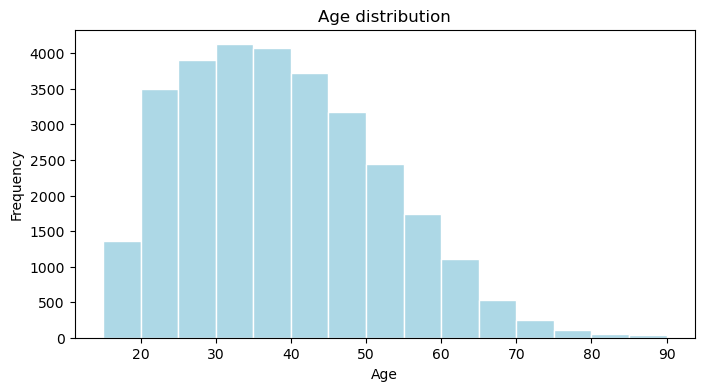

In [21]:
census["age"].plot(kind="hist", bins=range(15, 95, 5), color="lightblue", edgecolor="white", figsize=(8, 4))
plt.title("Age distribution")
plt.xlabel("Age")
plt.show()

In [22]:
(census["hours.per.week"] == 40).sum() / len(census) * 100 #percentage of workers working 40h per week

47.244434121901854

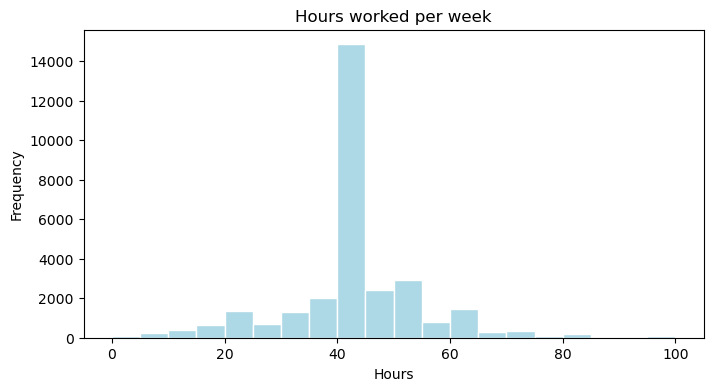

In [23]:
census["hours.per.week"].plot(kind="hist", bins=range(0, 105, 5), color="lightblue", edgecolor="white", figsize=(8, 4))
plt.title("Hours worked per week")
plt.xlabel("Hours")
plt.show()

In [24]:
print(census["sex"].value_counts(), "\n") #counting categories
print(census["race"].value_counts(), "\n")
print(census["workclass"].value_counts())

sex
Male      20366
Female     9773
Name: count, dtype: int64 

race
White                 25912
Black                  2816
Asian-Pac-Islander      894
Amer-Indian-Eskimo      286
Other                   231
Name: count, dtype: int64 

workclass
Private             22264
Self-emp-not-inc     2498
Local-gov            2067
State-gov            1279
Self-emp-inc         1074
Federal-gov           943
Without-pay            14
Name: count, dtype: int64
